In [1]:
import pandas as pd
df = pd.read_csv("../data/interim/pm25_long.csv", parse_dates=["timestamp"])
df["station"] = df["station"].str.replace("_Hourly", "")
wide = df.pivot(index="timestamp", columns="station", values="pm25")
print(wide.shape, wide.isna().sum().sum())

(11705, 6) 3


In [2]:
def longest_run(s):
    return (s != s.shift()).cumsum().value_counts().max()
print(wide.apply(longest_run))
print((wide >= 950).sum())  

station
AshokVihar     4
DCStadium      3
DwarkaSec8     3
Najafgarh      9
NehruNagar     3
Okhla         20
dtype: int64
station
AshokVihar     1
DCStadium      2
DwarkaSec8     1
Najafgarh      0
NehruNagar    10
Okhla          0
dtype: int64


<Axes: title={'center': 'Delhi mean PM2.5 (daily)'}, xlabel='timestamp'>

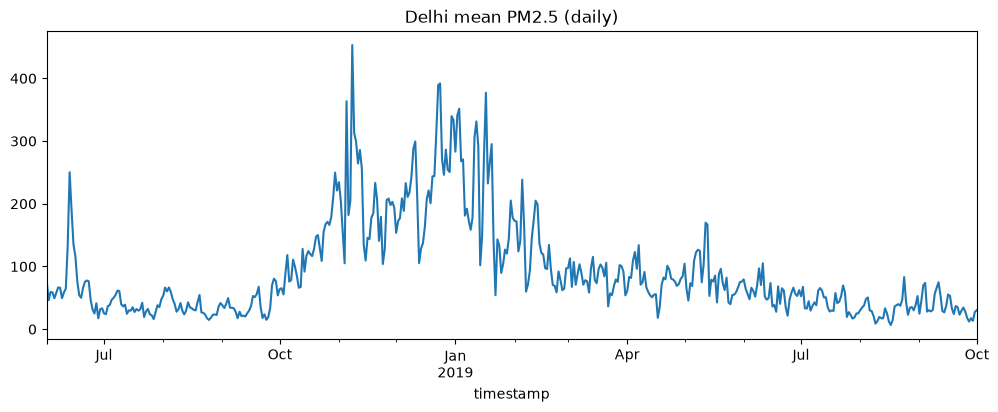

In [3]:
wide.mean(axis=1).resample("D").mean().plot(figsize=(12, 4), title="Delhi mean PM2.5 (daily)")

In [4]:
s = wide["Okhla"]
run_id = (s != s.shift()).cumsum()
runs = s.groupby(run_id).agg(["first", "size"])
longest = runs["size"].idxmax()
idx = s[run_id == longest].index
print(idx[0], idx[-1], runs.loc[longest, "first"])


2019-05-26 16:00:00 2019-05-27 11:00:00 22.0
